# Next-month link prediction: baselines

## 1. Setup and monthly snapshots

In [1]:
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt

DATA = os.environ.get("CHENNAI_DATA", "../../GNN-TRANSPORTATION/aadarsh-bikeshare/chennai")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.autolayout": True})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a9298"
key = lambda s: re.sub(r"[^a-z0-9]+", " ", str(s).lower().replace("\u2013", "-")).strip()

df = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="tripdata")
df = df.drop_duplicates().dropna(subset=["pickup_station", "drop_station"])
df = df[df.vehicle_type != "SmartBike"]
df["o"], df["d"] = df.pickup_station.map(key), df.drop_station.map(key)
df = df[~(df.o.str.contains("amma arangam|test") | df.d.str.contains("amma arangam|test"))]
df["month"] = pd.to_datetime(df.ride_start_time).dt.to_period("M")

nodes = sorted(set(df.o) | set(df.d)); ix = {n: i for i, n in enumerate(nodes)}; N = len(nodes)
months = sorted(df.month.unique()); T = len(months)

S = np.zeros((T, N, N))                        # S[t,i,j] = one-way trips in month t
for t, m in enumerate(months):
    g = df[(df.month == m) & (df.o != df.d)].groupby(["o", "d"]).size()
    for (o, d), w in g.items():
        S[t, ix[o], ix[d]] = w

st = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="109 live stations")
st.columns = [x.strip() for x in st.columns]
st = st.dropna(subset=["Station Name"]).copy(); st["o"] = st["Station Name"].map(key)
st.loc[st.Latitude > 90, "Latitude"] /= 1e6
st = st.drop_duplicates("o").set_index("o")
lat, lon = st.Latitude.reindex(nodes).values, st.Longitude.reindex(nodes).values

R = 6371.0; p = np.radians(np.c_[lat, lon])
hav = np.sin((p[:, None, 0] - p[None, :, 0]) / 2) ** 2 + \
      np.cos(p[:, None, 0]) * np.cos(p[None, :, 0]) * np.sin((p[:, None, 1] - p[None, :, 1]) / 2) ** 2
DIST = 2 * R * np.arcsin(np.sqrt(hav))
HAS_XY = np.isfinite(DIST)
DIST = np.where(HAS_XY, DIST, np.nanmedian(DIST))      # impute, and keep a flag feature

OFFDIAG = ~np.eye(N, dtype=bool)                        # the 12,882 candidate pairs
print(f"{N} stations, {T} months, {OFFDIAG.sum():,} candidate directed pairs")
print(f"active pairs per month: mean {np.mean([(S[t] > 0).sum() for t in range(T)]):.0f}")

114 stations, 20 months, 12,882 candidate directed pairs
active pairs per month: mean 1075


## 2. Features — everything strictly before the target month

In [2]:
def features(t):
    """Pair features for predicting month t, using months 0..t-1 only."""
    prev  = S[t-1]                       # last month
    hist  = S[:t].sum(0)                 # all history
    act   = (S[:t] > 0).sum(0)           # months the pair was active
    out_i = prev.sum(1, keepdims=True)   # origin volume last month
    in_j  = prev.sum(0, keepdims=True)   # destination volume last month
    f = {
        "log_trips_prev":  np.log1p(prev),
        "log_trips_hist":  np.log1p(hist),
        "frac_active":     act / t,
        "log_out_origin":  np.log1p(np.broadcast_to(out_i, prev.shape)),
        "log_in_dest":     np.log1p(np.broadcast_to(in_j, prev.shape)),
        "log_distance":    np.log1p(DIST),
        "reverse_active":  (prev.T > 0).astype(float),
    }
    X = np.stack([v[OFFDIAG] for v in f.values()], axis=1)
    return X, list(f)

def labels(t):
    return (S[t] > 0)[OFFDIAG].astype(float)

def subgroup(t):
    """recurring = active last month, returning = active earlier, novel = never active."""
    prev = (S[t-1] > 0)[OFFDIAG]
    ever = (S[:t] > 0).any(0)[OFFDIAG]
    g = np.full(OFFDIAG.sum(), "novel", dtype=object)
    g[ever & ~prev] = "returning"
    g[prev] = "recurring"
    return g

X0, FEATURES = features(6)
print("features:", FEATURES, "| matrix", X0.shape)

features: ['log_trips_prev', 'log_trips_hist', 'frac_active', 'log_out_origin', 'log_in_dest', 'log_distance', 'reverse_active'] | matrix (12882, 7)


## 3. Metrics

In [3]:
def auc(y, s):
    o = np.argsort(s); r = np.empty(len(s)); r[o] = np.arange(1, len(s) + 1)
    pos, neg = y.sum(), len(y) - y.sum()
    return (r[y == 1].sum() - pos * (pos + 1) / 2) / (pos * neg)

def ap(y, s):
    o = np.argsort(-s); y = y[o]
    prec = np.cumsum(y) / np.arange(1, len(y) + 1)
    return (prec * y).sum() / y.sum()

def p_at_k(y, s, k=None):
    k = int(y.sum()) if k is None else k
    return y[np.argsort(-s)[:k]].mean()

def recall_at_k(y, s, k=500):
    return y[np.argsort(-s)[:k]].sum() / y.sum()

## 4. Models

In [4]:
def persist_last(t):            # B0a: score = trips last month
    return S[t-1][OFFDIAG]

def persist_any(t):              # B0b: score = total trips in all past months
    return S[:t].sum(0)[OFFDIAG]

def logistic(Xtr, ytr, Xte, epochs=400, lr=.5):     # B1: plain gradient descent, no sklearn needed
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
    A_ = np.c_[(Xtr - mu) / sd, np.ones(len(Xtr))]
    B_ = np.c_[(Xte - mu) / sd, np.ones(len(Xte))]
    w = np.zeros(A_.shape[1])
    for _ in range(epochs):
        w -= lr * A_.T @ (1 / (1 + np.exp(-A_ @ w)) - ytr) / len(ytr)
    return 1 / (1 + np.exp(-B_ @ w)), w

## 5. Rolling folds

In [5]:
WARMUP, FIRST_TEST = 4, 6          # train starts at month 4, first test month is index 6
folds = list(range(FIRST_TEST, T))

rows, preds = [], {}
for t in folds:
    Xtr = np.vstack([features(j)[0] for j in range(WARMUP, t)])
    ytr = np.concatenate([labels(j) for j in range(WARMUP, t)])
    Xte, yte = features(t)[0], labels(t)
    s_log, w = logistic(Xtr, ytr, Xte)
    scores = {"B0a persistence": persist_last(t), "B0b any past": persist_any(t), "B1 logistic": s_log}
    preds[t] = (yte, scores, subgroup(t))
    for name, s in scores.items():
        rows.append({"test_month": str(months[t]), "model": name, "positives": int(yte.sum()),
                     "AP": ap(yte, s), "AUC": auc(yte, s),
                     "P@k": p_at_k(yte, s), "R@500": recall_at_k(yte, s)})

res = pd.DataFrame(rows)
print(f"{len(folds)} folds | mean positives {res.positives.mean():.0f} "
      f"({res.positives.mean()/OFFDIAG.sum():.1%} of candidates)")
res.groupby("model")[["AP", "AUC", "P@k", "R@500"]].agg(["mean", "std"]).round(3)

14 folds | mean positives 1239 (9.6% of candidates)


AP           AUC           P@k         R@500       
                  mean    std   mean    std   mean    std   mean    std
model                                                                  
B0a persistence  0.424  0.053  0.687  0.042  0.442  0.048  0.276  0.036
B0b any past     0.534  0.043  0.823  0.030  0.513  0.031  0.303  0.037
B1 logistic      0.571  0.045  0.875  0.014  0.537  0.033  0.310  0.038

## 6. Per-fold results

model       B0a persistence  B0b any past  B1 logistic  positives
test_month                                                       
2021-07               0.402         0.557        0.596       1079
2021-08               0.435         0.511        0.570       1239
2021-09               0.453         0.521        0.590       1541
2021-10               0.507         0.561        0.634       1537
2021-11               0.400         0.424        0.467        606
2021-12               0.307         0.519        0.543       1130
2022-01               0.345         0.472        0.493       1094
2022-02               0.382         0.544        0.563       1210
2022-03               0.457         0.585        0.617       1367
2022-04               0.465         0.558        0.591       1315
2022-05               0.459         0.558        0.595       1371
2022-06               0.436         0.553        0.576       1215
2022-07               0.427         0.560        0.573       1342
2022-08   

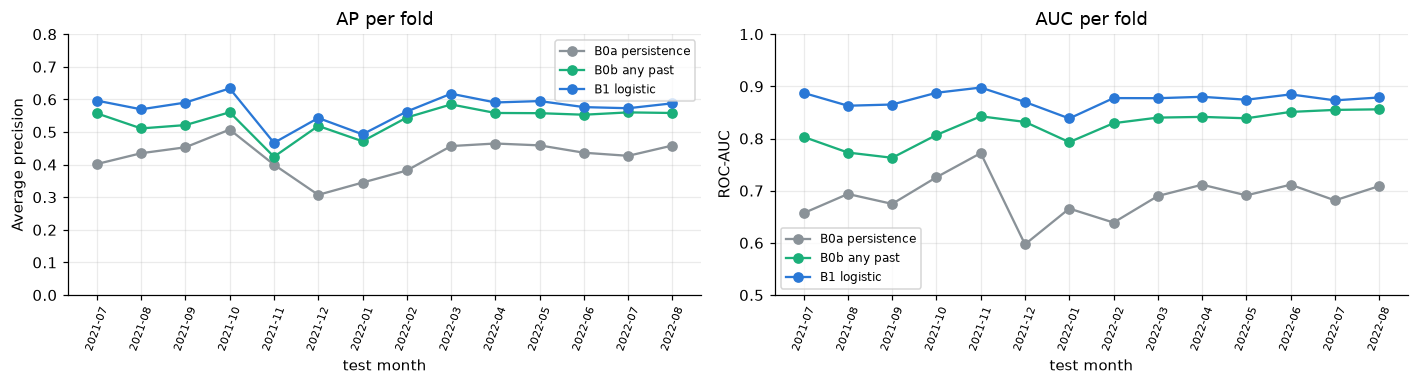

In [6]:
piv = res.pivot(index="test_month", columns="model", values="AP").round(3)
piv["positives"] = res.groupby("test_month").positives.first()
print(piv.to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for name, col in zip(["B0a persistence", "B0b any past", "B1 logistic"], [GREY, GREEN, BLUE]):
    d = res[res.model == name]
    ax[0].plot(d.test_month, d.AP, "o-", color=col, label=name)
    ax[1].plot(d.test_month, d.AUC, "o-", color=col, label=name)
ax[0].set(ylabel="Average precision", xlabel="test month", title="AP per fold", ylim=(0, .8))
ax[1].set(ylabel="ROC-AUC", xlabel="test month", title="AUC per fold", ylim=(.5, 1))
for a in ax: a.tick_params(axis="x", rotation=70, labelsize=7); a.legend(fontsize=8)
plt.show()

## 7. Where the models actually differ: by pair type

AP computed within each pair type

model      B0a persistence  B0b any past  B1 logistic  mean support
group                                                              
recurring            0.743         0.811        0.814         557.0
returning            0.161         0.334        0.381         421.0
novel                0.033         0.033        0.100         262.0


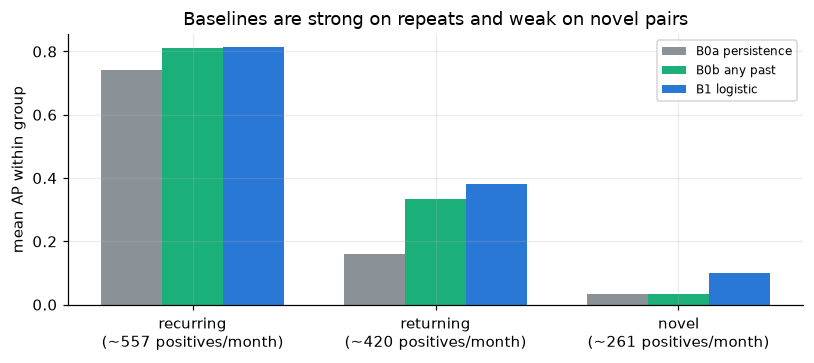

In [7]:
sub = []
for t, (yte, scores, grp) in preds.items():
    for g in ["recurring", "returning", "novel"]:
        m = grp == g
        if yte[m].sum() == 0: continue
        for name, s in scores.items():
            sub.append({"test_month": str(months[t]), "group": g, "model": name,
                        "support": int(yte[m].sum()), "candidates": int(m.sum()),
                        "AP": ap(yte[m], s[m])})
sub = pd.DataFrame(sub)

tbl = sub.pivot_table(index="group", columns="model", values="AP").reindex(["recurring", "returning", "novel"])
tbl["mean support"] = sub.groupby("group").support.mean().round(0)
print("AP computed within each pair type\n")
print(tbl.round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
g_order = ["recurring", "returning", "novel"]
w_ = .25
for i, (name, col) in enumerate(zip(["B0a persistence", "B0b any past", "B1 logistic"], [GREY, GREEN, BLUE])):
    v = [sub[(sub.group == g) & (sub.model == name)].AP.mean() for g in g_order]
    ax.bar(np.arange(3) + i * w_, v, width=w_, color=col, label=name)
ax.set(xticks=np.arange(3) + w_, ylabel="mean AP within group",
       title="Baselines are strong on repeats and weak on novel pairs")
ax.set_xticklabels([f"{g}\n(~{int(sub[sub.group==g].support.mean())} positives/month)" for g in g_order])
ax.legend(fontsize=8)
plt.show()

## 8. What the logistic model learned

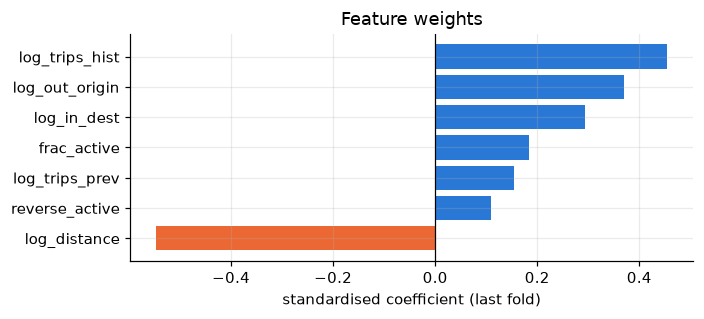

In [8]:
coef = pd.Series(w[:-1], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(coef.index, coef.values, color=[ORANGE if v < 0 else BLUE for v in coef.values])
ax.axvline(0, color="k", lw=.8)
ax.set(xlabel="standardised coefficient (last fold)", title="Feature weights")
plt.show()

## 9. Save predictions for later comparison

In [9]:
OUT = "outputs/results"; os.makedirs(OUT, exist_ok=True)
res.to_csv(f"{OUT}/baseline_results.csv", index=False)
sub.to_csv(f"{OUT}/baseline_results_by_group.csv", index=False)
np.savez_compressed(f"{OUT}/fold_predictions.npz",
                    **{f"y_{months[t]}": preds[t][0] for t in folds},
                    **{f"B1_{months[t]}": preds[t][1]["B1 logistic"] for t in folds})
manifest = pd.DataFrame([{"fold": i, "train_months": f"{months[WARMUP]}..{months[t-1]}",
                          "test_month": str(months[t]), "candidates": int(OFFDIAG.sum()),
                          "positives": int(labels(t).sum())} for i, t in enumerate(folds)])
manifest.to_csv(f"{OUT}/fold_manifest.csv", index=False)
print(manifest.to_string(index=False))

 fold     train_months test_month  candidates  positives
    0 2021-05..2021-06    2021-07       12882       1079
    1 2021-05..2021-07    2021-08       12882       1239
    2 2021-05..2021-08    2021-09       12882       1541
    3 2021-05..2021-09    2021-10       12882       1537
    4 2021-05..2021-10    2021-11       12882        606
    5 2021-05..2021-11    2021-12       12882       1130
    6 2021-05..2021-12    2022-01       12882       1094
    7 2021-05..2022-01    2022-02       12882       1210
    8 2021-05..2022-02    2022-03       12882       1367
    9 2021-05..2022-03    2022-04       12882       1315
   10 2021-05..2022-04    2022-05       12882       1371
   11 2021-05..2022-05    2022-06       12882       1215
   12 2021-05..2022-06    2022-07       12882       1342
   13 2021-05..2022-07    2022-08       12882       1306
